# 11 – Controlled experiments and temporal smoothing

This notebook summarises the additional experiments run after the main model comparison.
All runs use **SegFormer (MiT-B2), 10 m input, VV/VH/RATIO**, the **same spatial train/validation/test split** and the **same nine classes** as the baseline. Baseline outputs were not overwritten (results are in `outputs/evaluation/ablation/`).

| Run | Change compared with the baseline |
|---|---|
| Baseline | seed 42 |
| E1 | random seed 1 (measures run-to-run noise) |
| X3 | + month encoding (sin/cos of month) as extra input channels |
| X2b | cross-entropy weighted by Dynamic World label confidence (training only) |
| E3 | Lee speckle filter (5×5, ENL = 4.4·n_obs) applied to all splits |
| F1 | encoder trained from random weights (no ImageNet pre-training) |
| F2 / F3 | smaller (MiT-B0, 3.7 M) / larger (MiT-B4, 62 M) encoder instead of MiT-B2 (25 M) |
| F4 | cosine learning-rate schedule instead of OneCycle |
| F5 | learning rate 1e-4 instead of 3e-4 |
| F6 | no class weights in the cross-entropy loss |

In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

PROJ = "/home/jovyan/vault/heidelberg_lulc_2025"
ABL = f"{PROJ}/outputs/evaluation/ablation"
FIG = f"{PROJ}/outputs/figures"
os.makedirs(FIG, exist_ok=True)
RUNS = {"segformer_train10_VV-VH-RATIO_s42": "Baseline",
        "segformer_train10_abl-E1-seed1": "E1 seed 1",
        "segformer_train10_abl-X3-month": "X3 month enc.",
        "segformer_train10_abl-X2b-confweight": "X2b conf. weight",
        "segformer_train10_abl-E3-lee": "E3 Lee filter",
        "segformer_train10_ft-F1-scratch": "F1 no pre-training",
        "segformer_train10_ft-F2-mitb0": "F2 MiT-B0",
        "segformer_train10_ft-F3-mitb4": "F3 MiT-B4",
        "segformer_train10_ft-F4-cosine": "F4 cosine LR",
        "segformer_train10_ft-F5-lr1e-4": "F5 lr 1e-4",
        "segformer_train10_ft-F6-noclassweight": "F6 no class weights"}

## 1. Overall metrics on validation and test (10 m)

In [2]:
val = pd.read_csv(f"{ABL}/val/summary_overall.csv"); test = pd.read_csv(f"{ABL}/summary_overall.csv")
val, test = (d[(d["mode"] == "test10") & d.run.isin(RUNS)] for d in (val, test))
tab = (test.set_index("run")[["best_epoch", "OA", "mIoU", "mF1"]]
       .join(val.set_index("run")[["mIoU"]].rename(columns={"mIoU": "val_mIoU"})))
tab = tab.loc[[r for r in RUNS if r in tab.index]]
tab["delta_test_mIoU"] = tab["mIoU"] - tab.loc["segformer_train10_VV-VH-RATIO_s42", "mIoU"]
tab.index = tab.index.map(RUNS)
seed_noise = abs(tab.loc["E1 seed 1", "delta_test_mIoU"])
print(f"Seed-to-seed difference (noise level): {seed_noise:.3f} mIoU")
tab.round(4)

Seed-to-seed difference (noise level): 0.011 mIoU


,best_epoch,OA,mIoU,mF1,val_mIoU,delta_test_mIoU
run,,,,,,
Baseline,20,0.8321,0.4320,0.5374,0.4495,0.0000
E1 seed 1,23,0.8279,0.4433,0.5562,0.4530,0.0114
X3 month enc.,13,0.8277,0.4384,0.5497,0.4552,0.0064
X2b conf. weight,17,0.8299,0.4328,0.5411,0.4491,0.0008
E3 Lee filter,15,0.8264,0.4240,0.5316,0.4433,-0.0080
F1 no pre-training,32,0.7958,0.4000,0.5075,0.4137,-0.0319
F2 MiT-B0,30,0.8225,0.4316,0.5418,0.4525,-0.0004
F3 MiT-B4,12,0.8280,0.4315,0.5407,0.4490,-0.0005
F4 cosine LR,26,0.8206,0.4336,0.5418,0.4521,0.0016


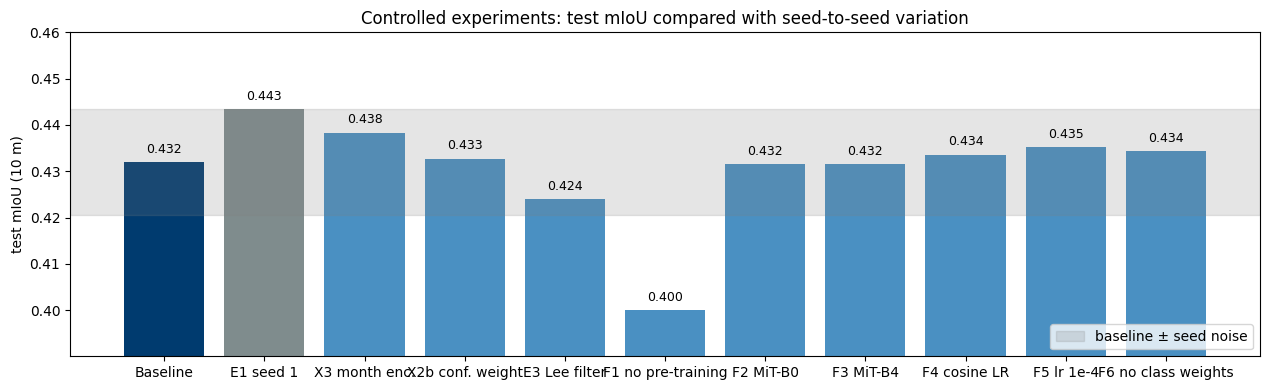

In [3]:
fig, ax = plt.subplots(figsize=(8 + 0.8 * max(0, len(tab) - 5), 4))
col = ["#003B6F" if n == "Baseline" else "#7F8C8D" if n.startswith("E1") else "#4A90C2" for n in tab.index]
ax.bar(tab.index, tab["mIoU"], color=col)
base = tab.loc["Baseline", "mIoU"]
ax.axhspan(base - seed_noise, base + seed_noise, color="grey", alpha=0.2, label="baseline ± seed noise")
for i, v in enumerate(tab["mIoU"]): ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylim(min(0.40, tab["mIoU"].min() - 0.01), max(0.46, tab["mIoU"].max() + 0.01)); ax.set_ylabel("test mIoU (10 m)"); ax.legend(loc="lower right")
ax.set_title("Controlled experiments: test mIoU compared with seed-to-seed variation")
plt.tight_layout(); plt.savefig(f"{FIG}/ablation_test_miou.png", dpi=200); plt.show()

## 2. Per-class IoU on test

In [4]:
pc = pd.read_csv(f"{ABL}/summary_per_class.csv")
pc = pc[(pc["mode"] == "test10") & pc.run.isin(RUNS)]
iou = pc.pivot(index="class", columns="run", values="IoU")[[r for r in RUNS if r in pc.run.unique()]]
iou.columns = iou.columns.map(RUNS)
iou.round(3)

run,Baseline,E1 seed 1,X3 month enc.,X2b conf. weight,E3 Lee filter,F1 no pre-training,F2 MiT-B0,F3 MiT-B4,F4 cosine LR,F5 lr 1e-4,F6 no class weights
class,,,,,,,,,,,
Bare ground,0.080,0.104,0.083,0.074,0.090,0.053,0.092,0.119,0.074,0.085,0.061
Built-up,0.844,0.843,0.840,0.844,0.837,0.821,0.840,0.844,0.845,0.843,0.846
Crops,0.730,0.728,0.713,0.716,0.716,0.666,0.714,0.717,0.715,0.725,0.727
Flooded vegetation,0.041,0.089,0.100,0.080,0.080,0.058,0.057,0.077,0.060,0.076,0.042
Grass,0.338,0.342,0.344,0.321,0.321,0.310,0.329,0.345,0.335,0.339,0.339
Shrub and scrub,0.166,0.174,0.155,0.149,0.097,0.122,0.165,0.152,0.169,0.155,0.164
Snow and ice,0.233,0.258,0.252,0.255,0.257,0.215,0.260,0.179,0.255,0.260,0.247
Trees,0.788,0.780,0.788,0.791,0.788,0.747,0.775,0.785,0.772,0.770,0.803
Water,0.669,0.672,0.671,0.666,0.631,0.609,0.653,0.665,0.678,0.664,0.680


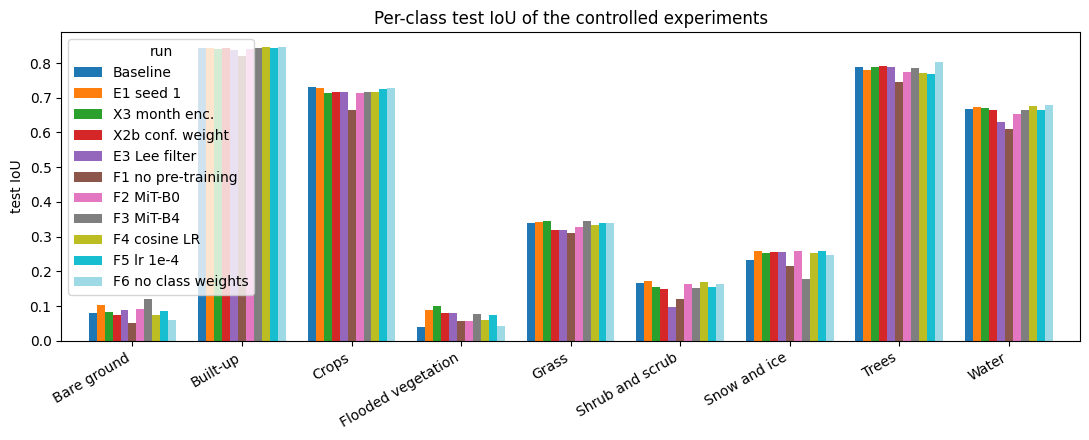

In [5]:
ax = iou.plot.bar(figsize=(11, 4.5), width=0.8, colormap="tab20")
ax.set_ylabel("test IoU"); ax.set_xlabel(""); ax.set_title("Per-class test IoU of the controlled experiments")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig(f"{FIG}/ablation_per_class_iou.png", dpi=200); plt.show()

## 3. Training curves of the experiments

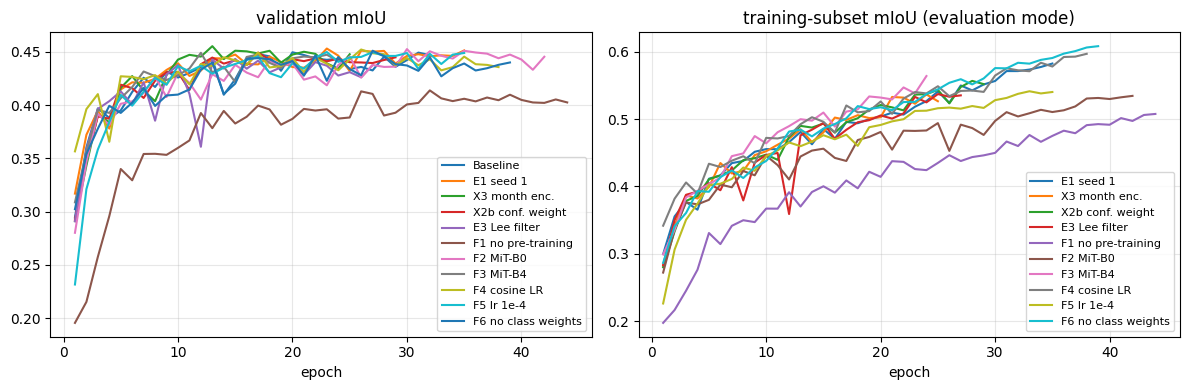

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for run, name in RUNS.items():
    f = f"{PROJ}/logs/{run}/history.csv"
    if not os.path.exists(f): continue
    h = pd.read_csv(f)
    vcol = [c for c in h.columns if "val" in c and "miou" in c.lower()][0]
    ax[0].plot(h["epoch"] if "epoch" in h else np.arange(1, len(h) + 1), h[vcol], label=name)
    tcol = [c for c in h.columns if "train" in c.lower() and "miou" in c.lower()]
    if tcol: ax[1].plot(np.arange(1, len(h) + 1), h[tcol[0]], label=name)
ax[0].set_title("validation mIoU"); ax[1].set_title("training-subset mIoU (evaluation mode)")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/ablation_training_curves.png", dpi=200); plt.show()

## 4. Temporal smoothing of the prototype outputs

Post-processing of the 12 monthly maps produced by the prototype (SegFormer 10 m, 10 km × 10 km, January–December 2025):
* **majority3** – each month takes the majority class of the previous, current and next month;
* **persistence** – a pixel changes class only if the new class persists for at least two consecutive months.

*Gross change* = share of pixels whose class differs from the previous month.

In [7]:
sm = pd.read_csv(f"{PROJ}/prototype/results/temporal_smoothing/summary.csv")
sm.round(2)

,site,method,mean_gross_change_%,mean_gross_change_summer_%,max_abs_monthly_built_up_pp,total_built_up_change_pp,first_last_gross_change_%,pixels_modified_vs_raw_%
0,Cairo,raw,2.77,2.36,1.82,1.70,4.38,0.00
1,Cairo,majority3,1.20,1.00,0.96,1.70,4.38,1.00
2,Cairo,persistence,0.74,0.65,0.84,2.47,3.92,1.08
3,Cairo (40 m),raw,2.41,2.38,1.69,-2.10,4.34,0.00
4,Cairo (40 m),majority3,1.11,0.90,1.04,-2.10,4.34,0.84
5,Cairo (40 m),persistence,0.72,0.66,0.71,-1.03,3.36,0.88
6,Munich,raw,3.67,2.49,5.35,1.32,4.30,0.00
7,Munich,majority3,1.47,1.07,1.65,1.32,4.30,1.22
8,Munich,persistence,1.00,0.76,1.58,0.81,4.11,1.38
9,Stuttgart,raw,7.43,4.44,5.59,-7.79,19.88,0.00


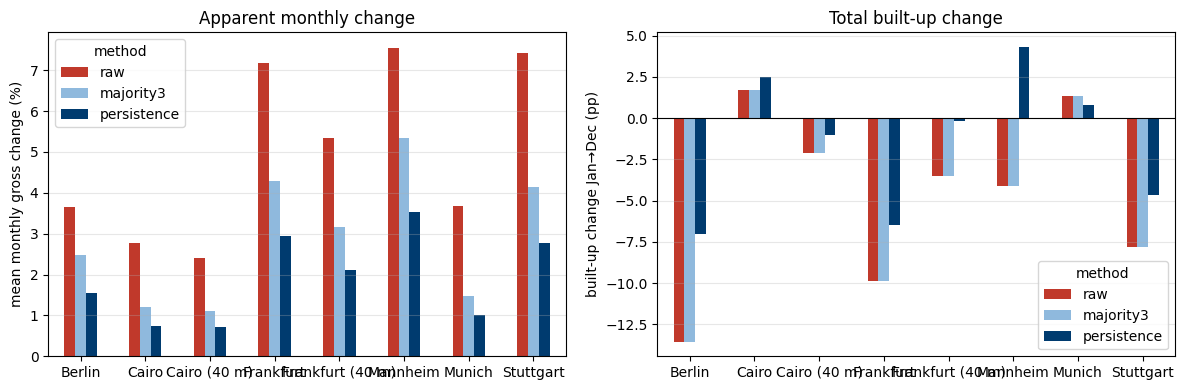

In [8]:
p = sm.pivot(index="site", columns="method", values="mean_gross_change_%")[["raw", "majority3", "persistence"]]
q = sm.pivot(index="site", columns="method", values="total_built_up_change_pp")[["raw", "majority3", "persistence"]]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
p.plot.bar(ax=ax[0], color=["#C0392B", "#8FB9DD", "#003B6F"]); ax[0].set_ylabel("mean monthly gross change (%)")
q.plot.bar(ax=ax[1], color=["#C0392B", "#8FB9DD", "#003B6F"]); ax[1].set_ylabel("built-up change Jan→Dec (pp)")
ax[1].axhline(0, color="black", lw=0.8)
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=0); a.grid(axis="y", alpha=0.3)
ax[0].set_title("Apparent monthly change"); ax[1].set_title("Total built-up change")
plt.tight_layout(); plt.savefig(f"{FIG}/temporal_smoothing_summary.png", dpi=200); plt.show()

## 5. Conclusions

* Changing only the random seed changed test mIoU by about 0.01. None of the interventions exceeded this noise level (month encoding +0.006, confidence weighting +0.001), and the Lee speckle filter reduced test mIoU (−0.008), mainly for shrub (texture) and water (edges). The baseline configuration is therefore robust.
* Strong classes (built-up, trees, crops, water) were stable across runs; flooded vegetation, bare ground and snow varied strongly, because they have few, low-confidence and mostly winter test pixels.
* Temporal smoothing reduced apparent monthly change by 53–73 % while changing at most 2.7 % of pixels, but annual built-up changes of several percentage points remain in the German cities. In an arid site without winter effects (Cairo) the apparent change was much lower. Seasonal backscatter effects, not land-cover change, dominate the raw change statistics.